# TP: Machine Learning

## TP2: Classification (4h) 

In machine learning, classification is related to supervised learning approaches in which the algorithm fits from an annotated set of data. This learning phase is followed by a validation phase to evaluate the classification model through several metrics. Once the model is correctly validated, a generalization phase is used to classify new data.

The given dataset was produced by the World Health Organization. It pooled the evolution of 20 features for 15 years and among numerous countries. One of the goals of this TP2 is to visualize feature space and try to predict the development of countries.

**Objectives:**
- Visualize the feature space
- Discuss the feasibility of feature space separation
- Normalize the datasets
- Train a K-NN, a decision tree, a random forest and a SVM
- Visualize the decision boundary for each method
- Create a test dataset
- Compute AUC scores on a evaluation dataset
- Tune hyperparameters
- Visualize the modification of decision boundary for each tuning
- Discuss the limits of the four implementations

This TP has different **checkpoints**. Please call your teacher at the end of each checkpoint to validate your work. Any non validated work won't be taken into account in the notation


## STEP 1: Feature space visualization

You will work on the WHO dataset in the year 2000. This first step consists of choosing two features to perform a classification.

**TO DO 1.1**

If you are using jupyter-notebook, execute the following cell :

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np

df = pd.read_csv("data/Life_Expectancy_Data.csv")
df = df.dropna()
df.info()

df1 = df[(df.Year == 2000)]

<class 'pandas.DataFrame'>
Index: 1649 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1649 non-null   str    
 1   Year                             1649 non-null   int64  
 2   Status                           1649 non-null   str    
 3   Life_expectancy                  1649 non-null   float64
 4   Adult_mortality                  1649 non-null   float64
 5   Infant_deaths                    1649 non-null   int64  
 6   Alcohol                          1649 non-null   float64
 7   Percentage_expenditure           1649 non-null   float64
 8   Hepatitis_B                      1649 non-null   float64
 9   Measles                          1649 non-null   int64  
 10  BMI                              1649 non-null   float64
 11  Under-five_deaths                1649 non-null   int64  
 12  Polio                            164

Text(0.5, 1.0, 'BMI against Total_expenditure; red for developping and green for developed')

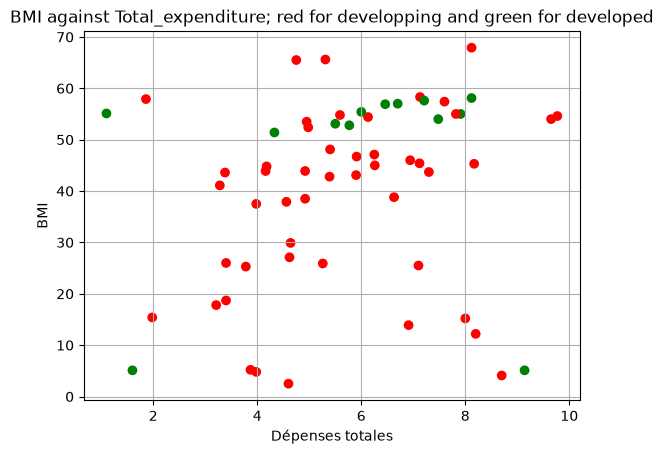

In [13]:
df_X = df1[['Total_expenditure', 'BMI']]
df_Status = df1[['Status']]

df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])

np1 = df_X.to_numpy()
plt.scatter(np1[:,0], np1[:,1], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt.grid(True)
plt.xlabel('Dépenses totales')
plt.ylabel('BMI')
plt.title('BMI against Total_expenditure; red for developping and green for developed')

**QUESTION 1**

Why was the label status binarized?

Is this feature space easily separable? Justify your response

La binarisation de la variable permet d'appliquer les modèles du cours et de simplifier l'interprétation (présence ou non d'une condition par exemple).

Il n'existe aucun hyperplan pouvant isoler les points rouges des points verts, donc l'espace n'est pas séparable facilement.

**TO CODE 1.2**

Plot Total expenditure against Schooling

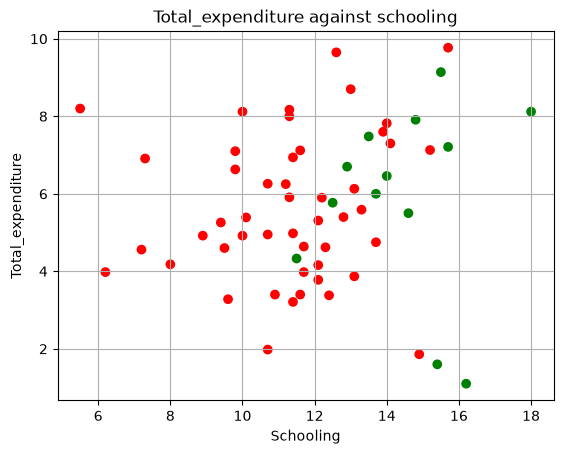

In [15]:
df_X_12 = df1[['Schooling', 'Total_expenditure']]
df_Y12 = df1[['Status']].replace(['Developing', 'Developed'], [0, 1])

np12 = df_X_12.to_numpy()
plt.scatter(np12[:,0], np12[:,1], c=np.squeeze(df_Y12.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt.xlabel('Schooling')
plt.ylabel('Total_expenditure')
plt.title('Total_expenditure against schooling')
plt.grid(True)
plt.show()

**TO CODE 1.3**

Plot Life Expectancy against Schooling

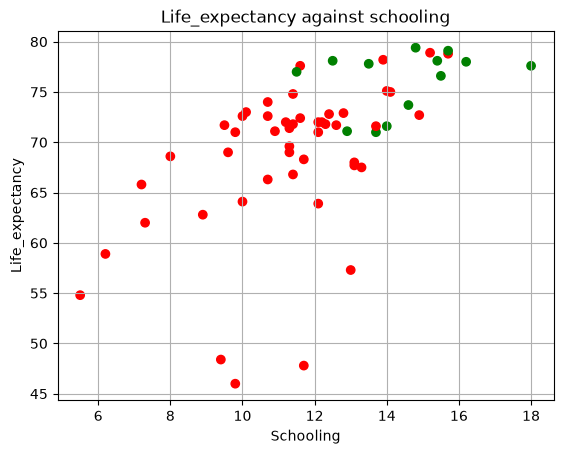

In [16]:
df_X13 = df1[['Schooling', 'Life_expectancy']]
df_Y13 = df1[['Status']].replace(['Developing', 'Developed'], [0, 1])

np13 = df_X13.to_numpy()
plt.scatter(np13[:,0], np13[:,1], c=np.squeeze(df_Y13.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt.xlabel('Schooling')
plt.ylabel('Life_expectancy')
plt.title('Life_expectancy against schooling')
plt.grid(True)
plt.show()

**QUESTION 2**

What would be the best features to use? Justify your response

Use those features as df_X.

On observe une corrélation linéaire positive entre espérance de vie et de la scolarisation, ce qui n'est pas le cas entre les dépenses totales et la scolarisation donc la meilleure variable à utiliser est l'espérance de vie.

## Checkpoint : 1
Call your teacher to validate the first step of the TP

## STEP 2: Dataset normalization

To classify, the values in the learning dataset must be normalized (aka between 0 and 1). This normalization can be performed through various ways.

**TO CODE 2.1**

Normalize df_X. This normalization should perfectly frame the data (aka the minimum and the maximum values of each feature should be respectively 0 and 1).

In [22]:
df_X = df1[['Life_expectancy', 'Schooling']]
#df_X_norm = (df_X - df_X.min()) / (df_X.max() - df_X.min()) cette ligne EST une erreur :
#en faisant ça on normalise les 2 colonnes selon 1 seul min et 1 seul max... La solution est la suivante :
df_X_norm = (df_X - df_X.min(axis=0)) / (df_X.max(axis=0) - df_X.min(axis=0))

**TO DO 2.2**

Each following cell performs a learning step and an AUC scores computation. For each classifier, several parameters have been chosen.

int64
(array([0, 1]), array([48, 13]))
Status    0
dtype: int64
(61, 2)


C:\Users\liamn\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


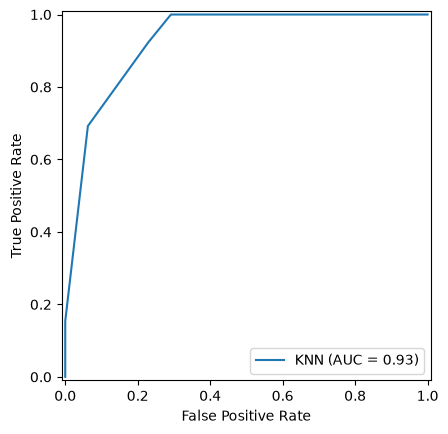

In [6]:
from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier

#.to_numpy() : convertit les données en tableaux NumPy, 
# qui seront utilisés pour entraîner les modèles de classification.
np_X_norm = df_X_norm.to_numpy()
#.astype(int) : convertit les valeurs de cette colonne en nombres entiers
np_Y = df_Y["Status"].astype(int).to_numpy()

 # KNeighborsClassifier le modèle regarde donc les 5 plus proches observations et donne sa classe :
clf1 = KNeighborsClassifier(n_neighbors=5)

# Le modèle calcule la probabilité qu'une observation appartienne à chacune des deux classes.
clf1.fit(np_X_norm, np_Y)

print(np_Y.dtype)
print(np.unique(np_Y, return_counts=True))
print(df_Y.isna().sum())

clf1 = KNeighborsClassifier(n_neighbors=5)
clf1.fit(np_X_norm, np_Y)
np_Y_pred = clf1.predict_proba(df_X_norm)
print(np_Y_pred.shape)

# tpr : taux de vrais positifs (sensibilité) et fpr : taux de faux positifs
fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])

# roc_auc : aire sous la courbe ROC.
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)

# Affiche le ROC du KNN
display.plot(name='KNN')
plt.show()

C:\Users\liamn\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\liamn\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


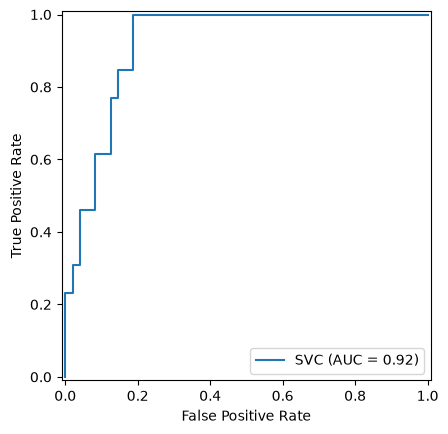

In [7]:
from sklearn.svm import SVC

clf2 = SVC(C=2.0, kernel='linear', probability=True)
clf2.fit(np_X_norm, np_Y)

np_Y_pred = clf2.predict_proba(df_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
display.plot(name='SVC')
plt.show()

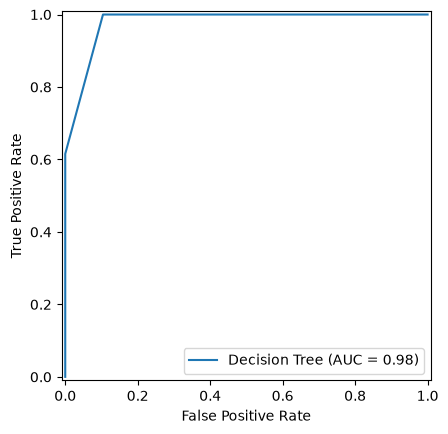

In [8]:
from sklearn.tree import DecisionTreeClassifier

clf3 = DecisionTreeClassifier(max_depth=3)
clf3.fit(np_X_norm, np_Y)

np_Y_pred = clf3.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
display.plot(name='Decision Tree')
plt.show()

C:\Users\liamn\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


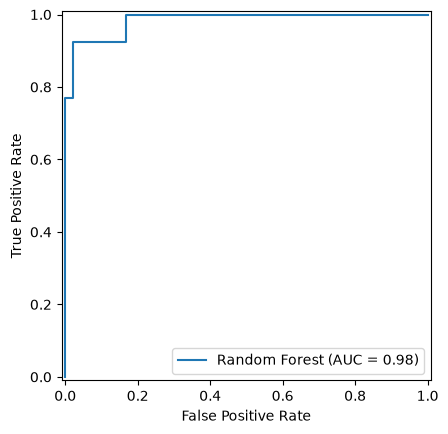

In [9]:
from sklearn.ensemble import RandomForestClassifier

clf4 = RandomForestClassifier(n_estimators=100, max_depth=3)
clf4.fit(np_X_norm, np_Y)

np_Y_pred = clf4.predict_proba(df_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
display.plot(name='Random Forest')
plt.show()

**QUESTION 3**

Identify each used classifiers and specify the used parameters

Describe and explain the results obtained for each ROC curve. What is the relation between the AUC and the ROC curve ? According to the ROC curve, which model is the best if we want to maximize the sensitivity ? And if we want to maximize the specificity ? Compare those results with the AUC. 

KNN : regarde les K points d'entraînement les plus proches, la classe majoritaire gagne.
n_neighbors = 5. Le modèle utilise les 5 plus proches voisins pour effectuer la classification.

SVM linéaire : regarde de quel côté de la frontière mathématique (hyperplan) tombe le nouveau point.
C = 2.0, kernel = 'linear' et probability = True. Le modèle cherche une frontière linéaire séparant au mieux les deux classes évalué par les probabilités.

Decision Tree : fait descendre le point dans un arbre de tests (ex: X > 5 ?) jusqu'à une classe finale. max_depth = 3 ce qui signifie 3 niveaux de décisions.

Random Forest : combine plusieurs Decision Trees, la classe qui obtient le plus de votes l'emporte.
n_estimators = 100 et max_depth = 3. Le modèle combine 100 arbres de décision ayant chacun 3 niveaux de décision.

La courbe ROC est obtenue en faisant varier le seuil de décision du classifieur et, pour chaque seuil, en calculant deux valeurs : le TPR (True Positive Rate / sensibilité) et le FPR (False Positive Rate).
Plus une courbe ROC est proche du coin supérieur gauche (aire importante), meilleur est le classifieur. La courbe ROC montre la capacité du modèle à détecter correctement les cas positifs, tout en limitant les erreurs où il classe à tort un cas négatif comme positif.
L'AUC correspond à l'aire située sous la courbe ROC. Elle résume donc la performance globale du classifieur : une AUC proche de 1 indique une très bonne classification.

On obtient les valeurs de AUC:
- KNN: 0,93 donc bonne classification
- SVM linéaire: 0,92 donc mauvaise classification
- Decision Tree: 0,98 donc très bonne classification
- Random Forest: 0, 98 donc meilleur classification
Le Decision Tree est donc pour l'instant le meilleur selon l'AUC, tandis que le SVM linéaire donne les moins bons résultat.

For a two-classes problem, a decision boundary is a hypersurface which splits the feature space between two sets (for each class). Then this surface is composed of all the equiprobability points in the feature space.

**TO DO 2.3**

Plot the decision boundary with df_X for each classifiers

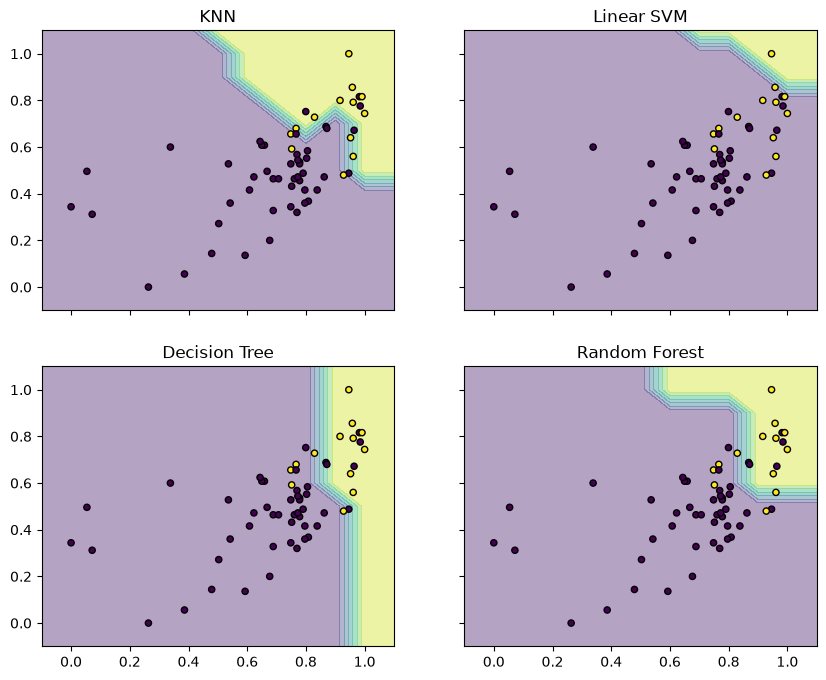

In [10]:
from itertools import product # Importe product pour générer les paires de coordonnées

# Calcul des limites de X et Y avec marge de 0.1 :
x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1 
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1 

 # Crée la matrice 2D pour l'axe X, pareil pour Y (pas de 0.1) :
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), 
                     np.arange(y_min, y_max, 0.1))

# Crée 4 graphiques (2x2) partageant les axes
f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8)) 

# Boucle sur les positions (0,0), (0,1), (1,0), (1,1) puis associe chaque modèle (classifieur) à la position
for idx, clf, tt in zip(product([0, 1], [0, 1]), 
                        [clf1, clf2, clf3, clf4], 
                        ['KNN', 'Linear SVM', 'Decision Tree', 'Random Forest']): 

# Aplatit la grille et prédit la classe de chaque point puis redonne la forme 2D initiale aux prédictions
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]) 
    Z = Z.reshape(xx.shape) 

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4) # Dessine les zones de couleurs (frontières de décision)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y, # Affiche les vrais points colorés par classe
                                  s=20, edgecolor='k') # Définit la taille des points et le bord noir
    axarr[idx[0], idx[1]].set_title(tt) # Affiche le nom du modèle en titre du graphique

**QUESTION 4**

What is the main problem of the classification step with this dataset?

In your opinion, which classifier is better suited for this classification task? Justify your response

Le pas de 0.1 est trop grand pour des axes allant de 0 à 1 ce qui rend les frontières de décision 
peu précises et donne un rendu visuel en escalier. 

Le Random Forest est le modèle qui a la meilleure frontière de décision, 
lisse et avec peu de sur-apprentissage. La classe jaune minoritaire est bien isolée en général.



## Checkpoint : 2
Call your teacher to validate the step 2

## STEP 3: Biases correction and model tuning

In this part, you will focus on improving the AUC scores of the four methods.

Firstable, you will weigh the classes to balance the classifier response. Then you will tune various hyperparameters.

**TO CODE 3.1**

Compute the percentage of "Developed" class in df_Y.

In [11]:
percentage_developed = df_Y["Status"].mean() * 100
print(percentage_developed , '%')

21.311475409836063 %


SVM, Decision Tree and Random Forest algorithms have a parameter named:

```
class_weight
```
Here is a extract from sklearn documentation:

**class_weight** dict, list of dict or “balanced”, default=None

Weights associated with classes in the form {class_label: weight}. If None, all classes are supposed to have weight one. For multi-output problems, a list of dicts can be provided in the same order as the columns of y.

The “balanced” mode uses the values of y to automatically adjust weights inversely proportional to class frequencies in the input data.


**QUESTION 5**

What would be the weight values for each class?

La classe Developed représente environ 21,31 % des données, contre 78,69 % pour la classe Developing. Avec l’option class_weight="balanced", les classes les moins représentées obtiennent un poids plus important. On obtient ainsi un poids d’environ 2,35 pour Developed et 0,64 pour Developing. Cela permet au modèle de mieux prendre en compte la classe minoritaire et de limiter le biais lié au déséquilibre des données.
T_Developed=1\(2*times0.2131)=2.35
T_Developing=1\(2*times0.7869)=0.64

**TO CODE 3.2**

Balance SVM, Decision Tree and Random Forest classifiers and plot the decision boundaries

**TO CODE 3.3**

Compute the new AUC scores

**QUESTION 6**

Why did the AUC scores increase? How do you interpret it?

In your opinion, has the classe balance improved the classification?


Let's focus on the SVM classifier.

Sklearn allows multiple kernels.

Here is an extract of the documentation:

**kernel** {‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’}, default=’rbf’

Specifies the kernel type to be used in the algorithm. It must be one of ‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’ or a callable. If none is given, ‘rbf’ will be used. If a callable is given it is used to pre-compute the kernel matrix from data matrices; that matrix should be an array of shape (n_samples, n_samples).


**TO CODE 3.4**

Test the gaussian and the polynomial kernels with balanced classes and plot the decision boundaries

**QUESTION 7**

In your opinion, which is the best kernel for this dataset? Justify your response

**BONUS**

Tune the parameters for Decision Tree and Random Forest algorithms and plot the decision boundaries

## Checkpoint : 3
Call your teacher to validate step 3

## STEP 4: An evaluation dataset

This part is to test the generalization of your models.

You trained several classifiers on two features extracted from the year 2000.

**TO CODE 4.1**

Apply your models on the year 2012

**QUESTION 8**

Are your models still relevant in the year 2012?

## Checkpoint : 4
Call your teacher to validate step 4. Congrats, you finished the second TP !